# **Section 4: Principal Component Analysis**

## **1. Principal Component Analysis**

Now that we have extracted and cleaned the CNV features, we can explore the data using a **Principal Component Analysis (PCA)**. A PCA projects the data onto several orthogonal axes called principal components. We can then plot the data and see if resistant and susceptible strains cluster together on the graphs. In this notebook, we will look at the training data set.

We will use **scikit-learn** to perform the PCA and label the srains according to their resistance profile.

#### **Contents**

1. **Load data**
2. **PCA**
    - **2.1. Scale the data**
    - **2.2. Perform the PCA**
    - **2.3. Scree plot**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

# Set style for plots
sns.set_style('whitegrid')
sns.set_palette("pastel")

## **1. Loading the data**

In [2]:
# Load features
cnv_data = pd.read_csv("Data/cnv_train_selected.csv", index_col=0)
X = cnv_data.values
print(f"CNV data shape: {X.shape}")

CNV data shape: (176, 4596)


In [3]:
# Load resistance profile metadata
SXT = pd.read_csv("Data/SXT_train_selected.csv", index_col=0)
y = SXT.values
print(f"Resistance profile shape: {SXT.shape}")

Resistance profile shape: (176, 1)


## **2. PCA**
### **2.1 Scale the Data**

In [4]:
# Create and apply StandardScaler
scaler = StandardScaler()
X_rescaled = scaler.fit_transform(X)

print(f"Mean of scaled features: {X_rescaled.mean(axis=0).mean()}")
print(f"Std of scaled features: {X_rescaled.std(axis=0).mean()}")

Mean of scaled features: 3.88106461984304e-18
Std of scaled features: 1.0


### **2.2 Perform PCA**

In [5]:
# Create and fit PCA with all components
pca = PCA(n_components=None)
X_pca = pca.fit_transform(X_rescaled)

print(f"PCA transformed data shape: {X_pca.shape}")

PCA transformed data shape: (176, 176)


### **2.3. Scree Plot**

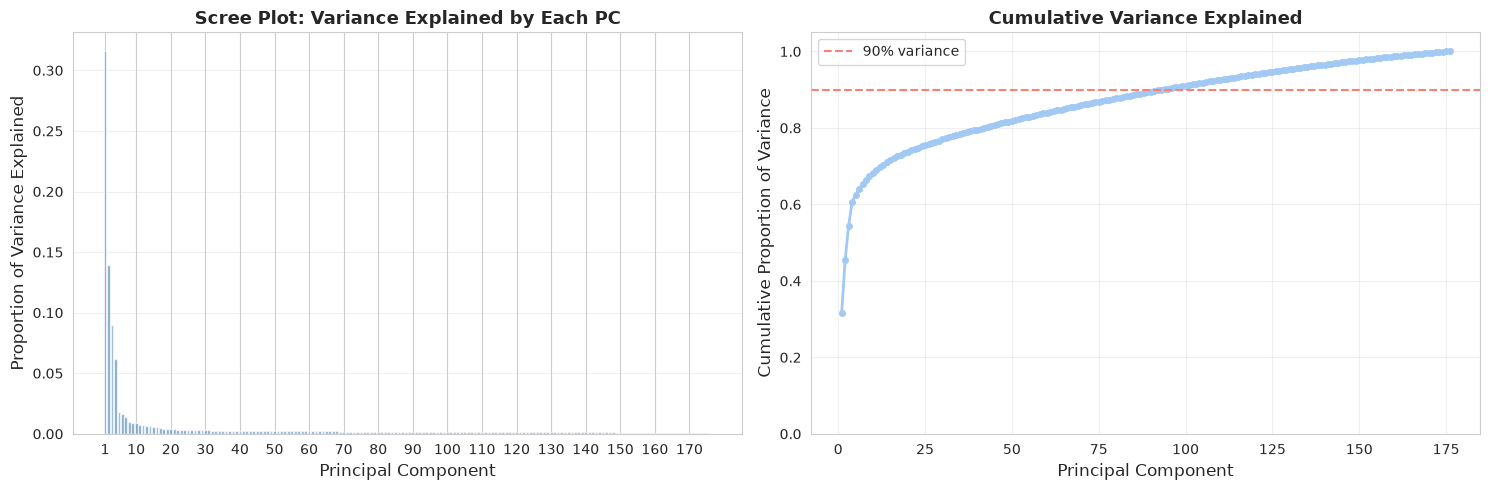

In [6]:
# Proportion of variance explained
pve = pca.explained_variance_ratio_
pve_cumsum = np.cumsum(pve)

# Create figure with scree plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Individual variance explained
components = np.arange(1, len(pve) + 1)
ax1.bar(components, pve, alpha=0.7, color='steelblue')
ax1.set_xticks([1] + list(np.arange(10, len(pve) + 1, 10)))
ax1.set_xlabel('Principal Component', fontsize=12)
ax1.set_ylabel('Proportion of Variance Explained', fontsize=12)
ax1.set_title('Scree Plot: Variance Explained by Each PC', fontsize=13, fontweight='bold')
ax1.grid(axis='y', alpha=0.3)

# Plot 2: Cumulative variance explained
ax2.plot(components, pve_cumsum, marker='o', linestyle='-', linewidth=2, markersize=4)
ax2.axhline(y=0.90, color='salmon', linestyle='--', label='90% variance')
ax2.set_xlabel('Principal Component', fontsize=12)
ax2.set_ylabel('Cumulative Proportion of Variance', fontsize=12)
ax2.set_title('Cumulative Variance Explained', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)
ax2.set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig("Figures/03_PCA.png", dpi=300, bbox_inches='tight')
plt.show()

In [7]:
# Print variance explained per threshold
thresholds = [0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95]
for threshold in thresholds:
    n_components = np.sum(pve_cumsum <= threshold)
    if n_components > 0:
        print(f"{int(n_components)} principal components explain {threshold*100:.0f}% of the variance")

print(f"\nFirst PC explains {pve_cumsum[0]*100:.2f}% of the variance")
print(f"First 2 PCs explain {pve_cumsum[1]*100:.2f}% of the variance")
print(f"First 3 PCs explain {pve_cumsum[2]*100:.2f}% of the variance")

2 principal components explain 50% of the variance
12 principal components explain 70% of the variance
41 principal components explain 80% of the variance
93 principal components explain 90% of the variance
127 principal components explain 95% of the variance

First PC explains 31.56% of the variance
First 2 PCs explain 45.51% of the variance
First 3 PCs explain 54.47% of the variance


Interestingly, the two first principal components do not explain a big proportion of the variance in our dataset. We see that we need to add several additional PCs to be able to explain a higher % of the variance. This could suggest that the features (the CNVs) are not very correlated to each other, and that the information about resistance is quite well distributed across the different features. 

### **2.4. Feature contribution to the first two PCs**
Let's now see which features contribute the most to the first two PCs. For this, we also need to load the **clusters.csv** file which contains the information about the clusters and features. 

In [11]:
cluster_info = pd.read_csv('Data/clusters.csv')
cluster_dict = cluster_info.groupby('cluster')['feature'].apply(list).to_dict()

In [12]:
# Create DataFrame with the weights of the loading vectors for the first two principal components
clusters = cnv_data.columns.tolist()
weights = pd.DataFrame(
    {
        "1st component": abs(pca.components_[0]),
        "2nd component": abs(pca.components_[1])
    },
    index=clusters
)

weights["feature_list"] = weights.index.map(lambda c: cluster_dict.get(int(c), []))

In [13]:
pd.set_option('display.max_colwidth', 200)
print("Top 5 clusters contributing to the 1st Principal Component:")
print(weights.sort_values(by="1st component", ascending=False)["feature_list"].head(5))

print("\nTop 5 clusters contributing to the 2nd Principal Component:")
print(weights.sort_values(by="2nd component", ascending=False)["feature_list"].head(5))

Top 5 clusters contributing to the 1st Principal Component:
278    [cnv_depth__IBNLCO_01739__Family__CDS, cnv_depth__IBNLCO_01739__IBNLCO_01739__gene, cnv_depth__IBNLCO_01737__IBNLCO_01737__gene, cnv_depth__IBNLCO_01737__Carrier__CDS, cnv_depth__IBNLCO_04733__IBN...
5      [cnv_depth__IBNLCO_00074__DNA__CDS, cnv_depth__IBNLCO_00074__IBNLCO_00074__gene, cnv_depth__IBNLCO_03396__IBNLCO_03396__gene, cnv_depth__IBNLCO_03396__ATP__CDS, cnv_depth__IBNLCO_00079__yidC__gene...
26     [cnv_depth__IBNLCO_00120__esaS__gene, cnv_depth__IBNLCO_00120__sensor__CDS, cnv_depth__IBNLCO_03093__Colicin__CDS, cnv_depth__IBNLCO_03093__IBNLCO_03093__gene, cnv_depth__IBNLCO_03434__IBNLCO_0343...
141    [cnv_depth__IBNLCO_01690__Cobalt-precorrin-5B__CDS, cnv_depth__IBNLCO_01690__IBNLCO_01690__gene, cnv_depth__IBNLCO_01987__Glycine__CDS, cnv_depth__IBNLCO_01987__IBNLCO_01987__gene, cnv_depth__IBNL...
28     [cnv_depth__IBNLCO_01708__ABC__CDS, cnv_depth__IBNLCO_01708__IBNLCO_01708__gene, cnv_depth__IBNLCO_01734_

interestingly, the clusters that contribute the most to the first PCs all seem to be clusters containing many different features. For the second PC, both small and large clusters contribute. At this stage, it is difficult to gain useful information here without digging deep into the genes and the litterature. Let's first see if the PCA can separate the clusters well.

### **2.5. Data visualization**

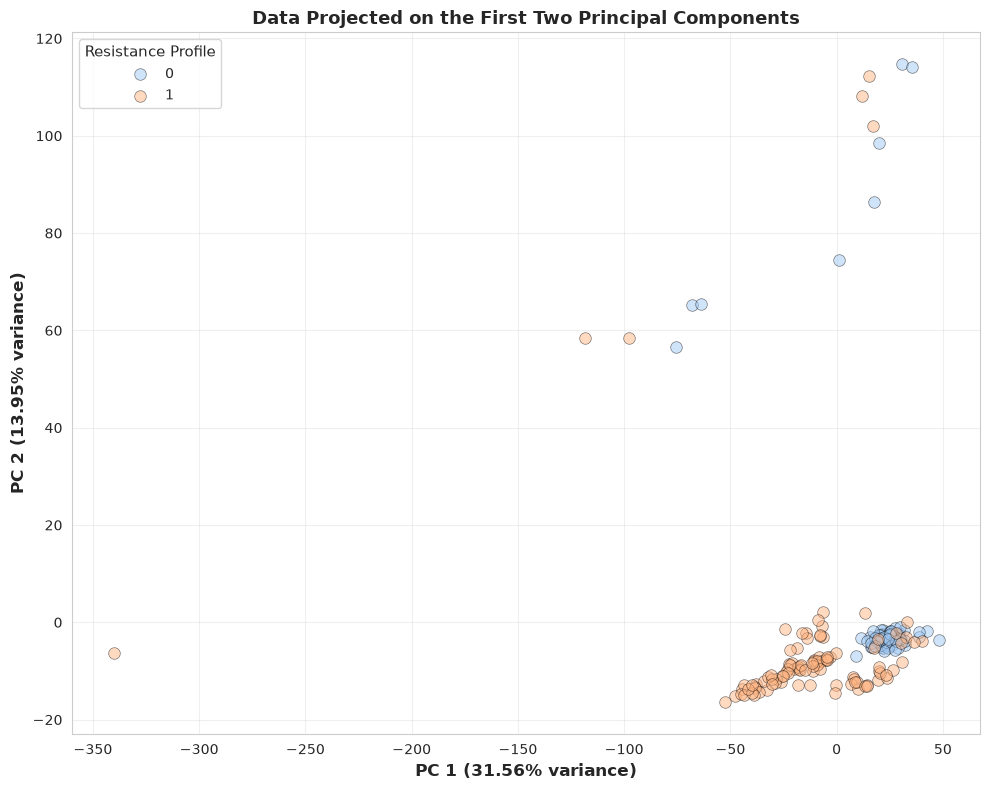

In [11]:
# Plot data projected onto first two PCs, colored by resistance profile
plt.figure(figsize=(10, 8))

profiles = np.unique(y)

for profile in profiles:
    idx = np.where(y == profile)[0]
    plt.scatter(X_pca[idx, 0], X_pca[idx, 1], label=profile, alpha=0.5, s=70, edgecolors='k', linewidth=0.5)

plt.xlabel(f'PC 1 ({pve[0]*100:.2f}% variance)', fontsize=12, fontweight='bold')
plt.ylabel(f'PC 2 ({pve[1]*100:.2f}% variance)', fontsize=12, fontweight='bold')
plt.title('Data Projected on the First Two Principal Components', fontsize=13, fontweight='bold')
plt.legend(loc='best', fontsize=10, title='Resistance Profile', title_fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/04_PCA_projection.png", dpi=300, bbox_inches='tight')
plt.show()

It looks like the first PC is actually able to somewhat distinguish between the resistant and susceptible strains. Indeed, on the bottom of the figure, we do see some clusters appearing. The second PC however seems to separate the strains based on something else. It will be interesting to see if the features chosen by a machine learning algorithm to predict resistance are similar to those contributing to the first PC. 